# Two-key optical encryption of QR codes

Digital twin of the off-axis holography bench. The diffuser and an offline-trained reference act as the two keys of an
optical cipher (main text, Fig. 3g,h; Supplementary Note 4C):

* **plaintext**: a QR code, stored in the signs of the interference term summed over each of its modules;
* **ciphertext**: a phase pattern $\theta_c$ on the $32\times32$ object cells, optimized through the diffuser, first through
  the ten-probe model of the object arm and then in situ;
* **key 1, the diffuser**: the object light is scrambled by it;
* **key 2, the reference pattern $E_K$** ($100\times100$ cells): designed offline through the reference-arm model.

Decryption is **one camera frame** with both keys. Reads with a flat reference, a wrong key or the intensity alone serve
as attacks. This demonstrates a physical two-key scheme, not a security proof.

| Section | In the manuscript |
|---|---|
| 1 · Plaintext: QR modules on the readout window | Supplementary Note 4C |
| 2 · Key 2: the reference $E_K$ and the realised key field | Supplementary Note 4C, Fig. S4a |
| 3 · Key 1: the ten-probe model of the diffuser | Eqs. (4)–(5); Supplementary Note 4C |
| 4 · Encryption: offline, then in situ | Eq. (S18); Fig. S4b |
| 5 · Decryption in one frame, and attacks | Fig. 3g,h; Fig. S4c |

The optics are in [`twin.py`](../Object/twin.py) and the reference arm and the two-arm bench in
[`reference.py`](reference.py). **On Colab:** upload `twin.py` and `reference.py` to the working directory; the first cell
installs `qrcode` and OpenCV. Runtime about 1 min on a laptop CPU.

In [1]:
import os
import sys
import time
import importlib.util
import subprocess

for package, module in [("qrcode", "qrcode"), ("opencv-python-headless", "cv2")]:
    if importlib.util.find_spec(module) is None:                 # e.g. on Colab
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", package], check=True, capture_output=True)
sys.path.append(os.path.join("..", "Object"))                    # twin.py; on Colab it sits next to this notebook

import numpy as np
import matplotlib.pyplot as plt
import qrcode
import cv2
import twin as tw
import reference as ref

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 9})
T_START = time.time()
bench = ref.Bench(seed=0)
W = ref.W90

## 1 · Plaintext: QR modules on the readout window

A version-2 QR code has $25\times25$ modules; each module covers $3\times3$ field pixels (60 µm), so the code fills 75 of the
90 pixels of the readout window. Modules fixed by the QR standard (finder patterns, separators, timing, alignment
pattern, dark module) carry no information and are restored from the standard before decoding; the centres of the three
finder patterns (always dark) are encrypted too and give the phase reference at decryption. All other modules carry the
message and are counted in the **content bit error rate**.

modules: fixed 236, message 389, phase reference 27
the plaintexts read back with OpenCV: ['LABORATORY OF PHOTONICS TECHNOLOGIES', 'HOLOGRAPHIC GRADIENTS']


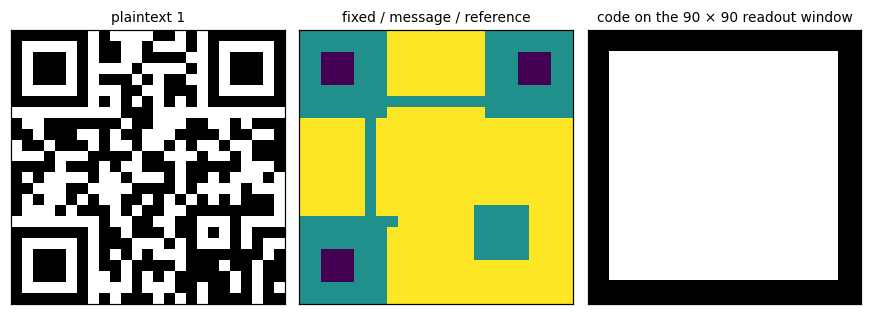

In [2]:
MESSAGES = ["LABORATORY OF PHOTONICS TECHNOLOGIES", "HOLOGRAPHIC GRADIENTS"]
NM, MOD, OFF = 25, 3, 7                                   # modules per side, pixels per module, offset in the window


def qr_matrix(text):
    q = qrcode.QRCode(version=2, error_correction=qrcode.constants.ERROR_CORRECT_M, border=0)
    q.add_data(text); q.make(fit=False)
    return np.array(q.get_matrix(), bool)                 # True = dark


FIXED = np.zeros((NM, NM), bool)
for r, c in [(0, 0), (0, NM - 8), (NM - 8, 0)]:
    FIXED[r:r + 8, c:c + 8] = True                        # finder patterns and separators
FIXED[6, :] = FIXED[:, 6] = True                          # timing
FIXED[16:21, 16:21] = True                                # alignment pattern
FIXED[NM - 8, 8] = True                                   # dark module
CORE = np.zeros((NM, NM), bool)
for r, c in [(2, 2), (2, NM - 5), (NM - 5, 2)]:
    CORE[r:r + 3, c:c + 3] = True                         # finder centres: the phase reference
CONTENT, USED = ~FIXED, ~FIXED | CORE                     # message modules; encrypted modules
STANDARD = qr_matrix("0")

MODULES = np.zeros((NM * NM, 90 * 90))                    # module -> window pixels
for i in range(NM):
    for j in range(NM):
        block = np.zeros((90, 90)); block[OFF + MOD * i:OFF + MOD * (i + 1), OFF + MOD * j:OFF + MOD * (j + 1)] = 1
        MODULES[NM * i + j] = block.ravel()
CODE = MODULES.sum(0).reshape(90, 90) > 0


def module_sums(d):
    # (..., 90, 90) -> (..., 625): the field summed over each module
    return d.reshape(d.shape[:-2] + (-1,)) @ MODULES.T


def decode_bits(z):
    # global phase from the reference modules (dark = -1), then dark where Re(z e^{-j alpha}) < 0
    alpha = np.angle(-np.sum(z[CORE.ravel()]))
    return np.real(z * np.exp(-1j * alpha)) < 0


def read_qr(dark):
    # restore the fixed modules and read the code with OpenCV
    m = np.where(FIXED.ravel(), STANDARD.ravel(), dark).reshape(NM, NM)
    img = cv2.resize(np.pad(np.where(m, 0, 255).astype(np.uint8), 4, constant_values=255), None, fx=10, fy=10,
                     interpolation=cv2.INTER_NEAREST)
    return cv2.QRCodeDetector().detectAndDecode(img)[0], m


print(f"modules: fixed {FIXED.sum()}, message {CONTENT.sum()}, phase reference {CORE.sum()}")
print("the plaintexts read back with OpenCV:", [read_qr(qr_matrix(m).ravel())[0] for m in MESSAGES])
fig, axs = plt.subplots(1, 3, figsize=(8, 2.8))
axs[0].imshow(qr_matrix(MESSAGES[0]), cmap="gray_r"); axs[0].set_title("plaintext 1")
axs[1].imshow(np.where(FIXED, 0.4, 1.0) - 0.6 * CORE, cmap="viridis"); axs[1].set_title("fixed / message / reference")
axs[2].imshow(CODE, cmap="gray"); axs[2].set_title("code on the 90 × 90 readout window")
for a in axs: a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## 2 · Key 2: the reference $E_K$

The key is a phase-only reference pattern, optimized through the reference-arm model so that $|R_K|$ is even over the
code (every module gets light) while its phase stays random:
$$L_K = \big\langle (I/\langle I\rangle - 1)^2\big\rangle_\text{code} - 0.1\,\log\frac{\sum_\text{code} I}{\sum_\text{window} I},
\qquad I = |T_R\{E_K\}|^2 .$$
A wrong key $E_W$ is made the same way from another random start. The key written on the bench differs from the model
(model error, SLM response), so the key holder measures the **realised** key field once, from paired reads of 60 random
object patterns with the flat reference ($\hat O_n$) and with the key ($d_n = O_n R_K^*$):
$\tilde R_K^* = \sum_n \hat O_n^* d_n / \sum_n |\hat O_n|^2$, pixel by pixel. It is used from then on.

In [3]:
CODE_GRID = np.zeros((tw.N, tw.N), bool); CODE_GRID[W, W] = CODE


def train_key(seed, steps=300):
    phi = 2 * np.pi * np.random.default_rng(seed).random((ref.NE, ref.NE))
    opt = tw.Adam((ref.NE, ref.NE), 0.05, 0.05)
    for _ in range(steps):
        E = np.exp(1j * phi)
        R = ref.MODEL.forward(E)
        I = np.abs(R)**2
        Ic, mean = I[CODE_GRID], I[CODE_GRID].mean()
        g = np.zeros((tw.N, tw.N))                                       # dL/dI
        r = Ic / mean - 1
        g[CODE_GRID] = 2 * (r - np.mean(r * Ic) / mean) / (mean * Ic.size) - 0.1 / Ic.sum()
        g[ref.WINDOW] += 0.1 / I[ref.WINDOW].sum()
        phi = opt.step(phi, 2 * np.imag(np.conj(E) * ref.MODEL.adjoint(g * R)))
    return np.exp(1j * phi)


def realised_key(E, n=60, seed=9):
    phases = 2 * np.pi * np.random.default_rng(seed).random((n, tw.NC, tw.NC))
    O, d = bench.acquire(phases)[:, W, W], ref.demodulate(bench.frame(phases, E))[:, W, W]
    return np.conj(np.sum(np.conj(O) * d, 0) / np.sum(np.abs(O)**2, 0))


E_K, E_W = train_key(101), train_key(202)
R_K = realised_key(E_K)
contrast = lambda I: I[CODE].std() / I[CODE].mean()
I_start = np.abs(ref.MODEL.forward(np.exp(2j * np.pi * np.random.default_rng(101).random((ref.NE, ref.NE))))[W, W])**2
print(f"key intensity contrast over the code (std/mean): random phase {contrast(I_start):.2f} -> key "
      f"{contrast(np.abs(ref.MODEL.forward(E_K)[W, W])**2):.2f}")
print(f"realised key vs model key on the code: correlation {tw.corr(R_K[CODE], ref.MODEL.forward(E_K)[W, W][CODE]):.3f}")

key intensity contrast over the code (std/mean): random phase 1.01 -> key 0.27
realised key vs model key on the code: correlation 0.989


## 3 · Key 1: the ten-probe model of the diffuser

To design a ciphertext, the object arm needs an adjoint: the thin-screen model $T_O \cong P_{z_s}\mathrm{diag}(D)P_{-z_s}F$
(Eq. 4), fitted from **10 random probes** read with the flat reference (Eq. 5, `tw.fit_screen`), on the readout window.

In [4]:
rng = np.random.default_rng(5)
P_probe, P_check = 2 * np.pi * rng.random((10, tw.NC, tw.NC)), 2 * np.pi * rng.random((40, tw.NC, tw.NC))
object_model = tw.fit_screen(np.exp(1j * P_probe), bench.acquire(P_probe), mask=ref.WINDOW)
Y_check = bench.acquire(P_check)
print(f"object model accuracy on the window (40 held-out patterns): "
      f"{tw.model_accuracy(object_model, np.exp(1j * P_check), Y_check, ref.WINDOW):.3f} "
      f"(free space only {tw.model_accuracy(tw.ObjectArm(), np.exp(1j * P_check), Y_check, ref.WINDOW):.3f}; bench 0.60)")

object model accuracy on the window (40 held-out patterns): 0.865 (free space only 0.149; bench 0.60)


## 4 · Encryption

For module $m$ the keyed read gives $z_m = \sum_{\mathbf x\in m} O R_K^*$; the bits are $b_m = -1$ (dark) or $+1$ (light).
The ciphertext minimizes a soft margin on every encrypted module (Supplementary Eq. S18),
$$L = \Big\langle \kappa^{-1}\,\mathrm{softplus}\big[\kappa(\mu - u_m)\big]\Big\rangle_m,\qquad
u_m = \frac{b_m\,\mathrm{Re}(z_m e^{-j\alpha})}{\mathrm{rms}\,|z|},\qquad \alpha = \arg\sum_m b_m z_m,$$
with $\kappa = 4$, $\mu = 0.5$. The error field is $W = \partial L/\partial O^* = (\partial L/\partial z_m^*)\,\tilde R_K$ on the
pixels of module $m$, and the gradient is that of the object arm, $\partial L/\partial\theta = 2\,\mathrm{Im}[X_O^*\odot
T_O^{\mathrm H}\{W\}]$ (Eq. 3):

1. **offline**, 400 Adam steps with $O$ predicted by the object model;
2. **in situ**, 150 steps, each with **one flat-reference read** of the ciphertext: the **measured** $\hat O$, rotated into the
   model's gauge, enters $z$ and $W$; the model supplies only the adjoint. The key is never displayed during encryption.

Every ten in situ steps, a check read with the key gives the content bit error rate (Fig. S4b).

In [5]:
def cipher_loss(O, bits, kappa=4.0, mu=0.5):
    # loss and error field dL/dO* on the window (alpha and the rms held fixed)
    z = module_sums(O * np.conj(R_K))
    used = USED.ravel()
    alpha = np.angle(np.sum(bits[used] * z[used]))
    rms = np.sqrt(np.mean(np.abs(z[used])**2))
    u = bits * np.real(z * np.exp(-1j * alpha)) / rms
    L = np.mean(np.logaddexp(0, kappa * (mu - u[used]))) / kappa
    dL_du = np.where(used, -1 / (1 + np.exp(-kappa * (mu - u))), 0) / used.sum()
    dL_dz = dL_du * bits / rms * 0.5 * np.exp(1j * alpha)
    W_err = (dL_dz @ MODULES).reshape(90, 90) * R_K
    return L, W_err


def content_ber(signs, truth):
    return np.mean((signs < 0)[CONTENT.ravel()] != truth[CONTENT.ravel()])


def encrypt(message, offline=400, insitu=150, seed=0):
    truth = qr_matrix(message).ravel()
    bits = np.where(truth, -1.0, 1.0)
    theta = np.random.default_rng(seed).uniform(-np.pi, np.pi, (tw.NC, tw.NC))
    opt = tw.Adam((tw.NC, tw.NC), 0.05, 0.05)
    checks = []
    for step in range(offline + insitu):
        X = np.exp(1j * theta)
        pred = object_model.forward(X)
        O = pred if step < offline else tw.to_model_gauge(bench.acquire(theta[None])[0], pred, ref.WINDOW)
        L, W_err = cipher_loss(O[W, W], bits)
        if step >= offline and (step - offline) % 10 == 0:                    # check read with the key
            checks.append((step, content_ber(-1.0 + 2 * ~decode_bits(module_sums(keyed_read(theta, E_K))), truth)))
        error_field = np.zeros((tw.N, tw.N), complex); error_field[W, W] = W_err
        theta = opt.step(theta, tw.object_gradient(X, error_field, object_model))
    return dict(theta=theta, checks=np.array(checks))


def keyed_read(theta, E):
    return ref.demodulate(bench.frame(theta[None], E))[0][W, W]


t0 = time.time()
ciphers = {m: encrypt(m, seed=k) for k, m in enumerate(MESSAGES)}
print(f"encrypted {len(MESSAGES)} messages in {time.time() - t0:.0f} s")
for k, (m, c) in enumerate(ciphers.items()):
    print(f"message {k + 1}: content BER of the keyed check reads, start / end of the in situ steps: "
          f"{c['checks'][0, 1]:.3f} / {c['checks'][-1, 1]:.3f}")

encrypted 2 messages in 33 s
message 1: content BER of the keyed check reads, start / end of the in situ steps: 0.028 / 0.023
message 2: content BER of the keyed check reads, start / end of the in situ steps: 0.036 / 0.013


## 5 · Decryption in one frame, and attacks

**Decryption:** write $\theta_c$ and the key $E_K$, take one frame, sum each module of the demodulated field, take the
phase from the reference modules, threshold the signs, restore the fixed modules and read the code with OpenCV. Each
message is decrypted ten times. **Attacks**, each one frame of the same ciphertext: a flat reference; the wrong key $E_W$;
and the intensity $|\hat O|^2$ summed per module, with threshold and polarity fitted on the reference modules.

In [6]:
def intensity_attack(theta):
    s = module_sums(np.abs(bench.acquire(theta[None])[0][W, W])**2)
    best = None
    for threshold in np.quantile(s[USED.ravel()], np.linspace(0.05, 0.95, 37)):
        for polarity in (1, -1):
            dark = polarity * (s - threshold) > 0
            errors = np.mean(~dark[CORE.ravel()])
            if best is None or errors < best[0]:
                best = (errors, dark)
    return best[1]


reads = {"key E_K": lambda th: decode_bits(module_sums(keyed_read(th, E_K))),
         "flat reference": lambda th: decode_bits(module_sums(keyed_read(th, ref.FLAT))),
         "wrong key E_W": lambda th: decode_bits(module_sums(keyed_read(th, E_W))),
         "intensity |O|²": intensity_attack}
results = {}
for m, c in ciphers.items():
    truth = qr_matrix(m).ravel()
    for name, read in reads.items():
        darks = [read(c["theta"]) for _ in range(10)]
        decoded = [read_qr(dark)[0] for dark in darks]
        results[m, name] = dict(ber=np.array([np.mean(dk[CONTENT.ravel()] != truth[CONTENT.ravel()]) for dk in darks]),
                                decoded=sum(text == m for text in decoded), example=read_qr(darks[0])[1])
print(f"{'read with':16s} " + " ".join(f"{'message ' + str(k + 1) + ': BER, decoded':>26s}" for k in range(len(MESSAGES))))
for name in reads:
    print(f"{name:16s} " + " ".join(f"{results[m, name]['ber'].mean():18.3f}, {results[m, name]['decoded']:2d}/10"
                                     for m in MESSAGES))

read with           message 1: BER, decoded    message 2: BER, decoded
key E_K                       0.023, 10/10              0.015, 10/10
flat reference                0.507,  0/10              0.486,  0/10
wrong key E_W                 0.481,  0/10              0.476,  0/10
intensity |O|²                0.524,  0/10              0.491,  0/10


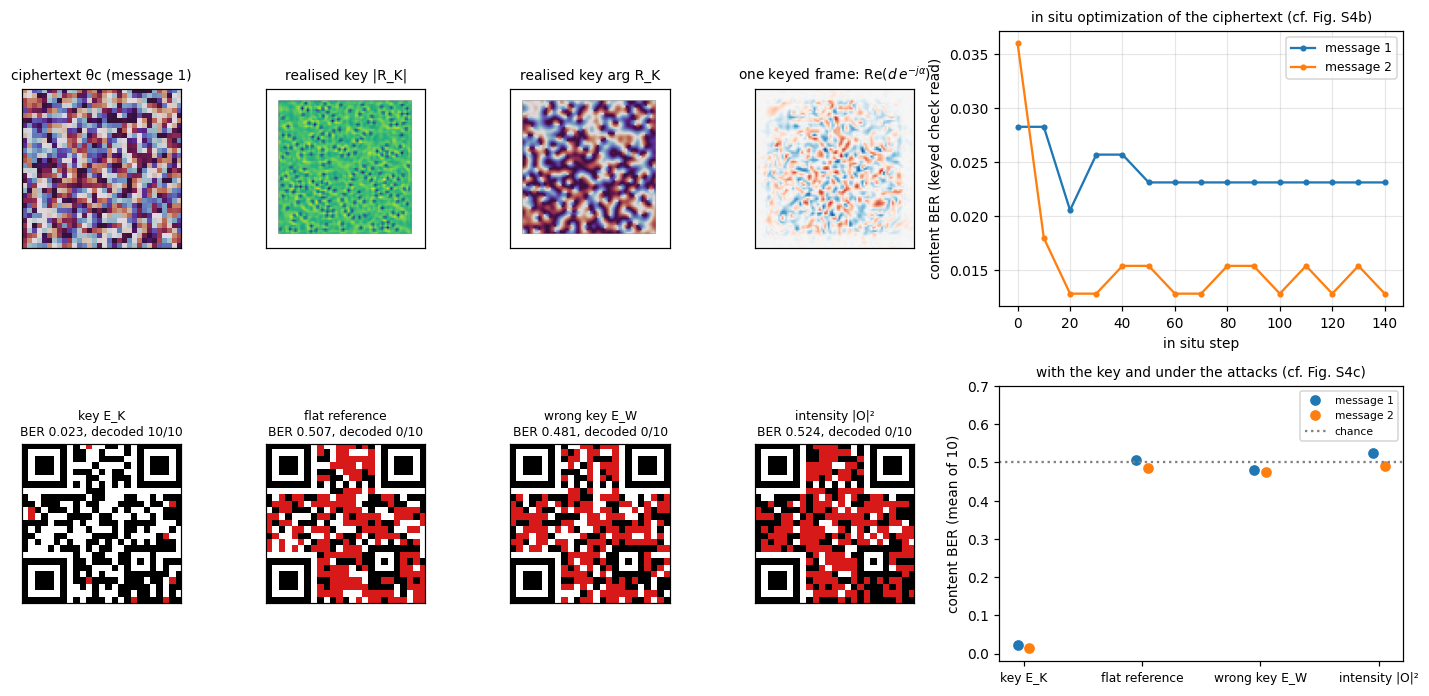

bench reads: 581; runtime 44 s


In [7]:
fig = plt.figure(figsize=(13, 6.4))
gs = fig.add_gridspec(2, 6)
ax = fig.add_subplot(gs[0, 0]); ax.imshow(np.mod(ciphers[MESSAGES[0]]["theta"], 2 * np.pi), cmap="twilight")
ax.set_title("ciphertext θc (message 1)")
ax = fig.add_subplot(gs[0, 1]); ax.imshow(np.where(CODE, np.abs(R_K), np.nan), cmap="viridis"); ax.set_title("realised key |R_K|")
ax = fig.add_subplot(gs[0, 2]); ax.imshow(np.where(CODE, np.angle(R_K), np.nan), cmap="twilight"); ax.set_title("realised key arg R_K")
d = keyed_read(ciphers[MESSAGES[0]]["theta"], E_K)
alpha = np.angle(-np.sum(module_sums(d)[CORE.ravel()]))
ax = fig.add_subplot(gs[0, 3]); v = np.abs(d).max()
ax.imshow(np.real(d * np.exp(-1j * alpha)), cmap="RdBu_r", vmin=-v, vmax=v); ax.set_title(r"one keyed frame: Re$(d\,e^{-j\alpha})$")
ax = fig.add_subplot(gs[0, 4:])
for k, (m, c) in enumerate(ciphers.items()):
    ax.plot(c["checks"][:, 0] - 400, c["checks"][:, 1], "o-", ms=3, label=f"message {k + 1}")
ax.set_xlabel("in situ step"); ax.set_ylabel("content BER (keyed check read)"); ax.grid(alpha=0.3); ax.legend(fontsize=8)
ax.set_title("in situ optimization of the ciphertext (cf. Fig. S4b)")
for a in fig.axes[:4]: a.set_xticks([]); a.set_yticks([])
truth = qr_matrix(MESSAGES[0])
for k, name in enumerate(reads):
    m = results[MESSAGES[0], name]["example"]
    rgb = np.stack([np.where(m, 0.0, 1.0)] * 3, -1)
    rgb[(m != truth) & CONTENT] = [0.85, 0.1, 0.1]
    ax = fig.add_subplot(gs[1, k]); ax.imshow(rgb); ax.set_xticks([]); ax.set_yticks([])
    r = results[MESSAGES[0], name]
    ax.set_title(f"{name}\nBER {r['ber'].mean():.3f}, decoded {r['decoded']}/10", fontsize=8)
ax = fig.add_subplot(gs[1, 4:])
for k, m in enumerate(MESSAGES):
    ax.plot(np.arange(len(reads)) + 0.1 * (k - 0.5), [results[m, n]["ber"].mean() for n in reads], "o", label=f"message {k + 1}")
ax.axhline(0.5, color="gray", ls=":", label="chance")
ax.set_xticks(range(len(reads))); ax.set_xticklabels(reads, fontsize=8); ax.set_ylim(-0.02, 0.7)
ax.set_ylabel("content BER (mean of 10)"); ax.legend(fontsize=7); ax.set_title("with the key and under the attacks (cf. Fig. S4c)")
plt.tight_layout(); plt.show()
print(f"bench reads: {bench.reads:,}; runtime {time.time() - T_START:.0f} s")

**Take-aways.** With both keys, one frame decrypts each QR code with a content bit error rate of 0.023 and
0.015 (mean of ten reads), and every decryption of both messages is read; the in situ steps, driven by the measured
field, lower it from 0.028 and 0.036 reached offline (bench: at most 0.014, every code read). Reads with a flat reference,
a wrong key or the intensity alone stay at chance (0.48–0.52) and are never read (bench: 0.46–0.54). The work is shared
between the arms: the object arm, through its ten-probe model and then in situ, shapes the pattern behind the diffuser,
and the reference arm carries the key that turns it into bits.